# Task 2 — Content Type Prediction Model
**Auspify Technologies | Machine Learning**

This notebook predicts whether a Netflix title is a **Movie** or **TV Show** using the provided `Dataset.csv`.

## Workflow
1. Load and inspect the real dataset.
2. Clean missing target values and inspect class balance.
3. Select useful features while excluding `type` from predictors and dropping identifiers/title text.
4. Split data into training and testing sets using stratification.
5. Train a Dummy baseline, Logistic Regression, Random Forest, and Extra Trees.
6. Compare Accuracy, Precision, Recall, weighted F1, and macro F1.
7. Evaluate the best non-baseline model with a confusion matrix and classification report.
8. Save the selected model and metrics.

**Important:** Run the notebook from the project root or use the path cell below. Keep the test set separate until final evaluation. Results are generated by execution, not hard-coded.

## 1. Import libraries and set paths

In [1]:
from pathlib import Path
import sys
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data/raw/Dataset.csv").exists():
    # Supports opening the notebook from inside the notebooks directory.
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data/raw/Dataset.csv"
MODELS_DIR = PROJECT_ROOT / "models"
METRICS_DIR = PROJECT_ROOT / "reports/metrics"
FIGURES_DIR = PROJECT_ROOT / "reports/figures"
for folder in [MODELS_DIR, METRICS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT.resolve())
print("Dataset exists:", DATA_PATH.exists())

Project root: /Users/mgs/Downloads/content-type-prediction
Dataset exists: True


## 2. Load and inspect the dataset

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Cannot find {DATA_PATH}. Ensure Dataset.csv is inside data/raw/."
    )

df_original = pd.read_csv(DATA_PATH)
print("Dataset shape:", df_original.shape)
display(df_original.head())
display(df_original.info())

Dataset shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


None

In [3]:
print("Column names:")
print(df_original.columns.tolist())

print("\nMissing values per column:")
display(df_original.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("\nDuplicate rows:", int(df_original.duplicated().sum()))

Column names:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Missing values per column:


,missing_count
show_id,0
type,0
title,0
director,0
country,0
date_added,0
release_year,0
rating,0
duration,0
listed_in,0



Duplicate rows: 0


## 3. Clean data and explore the target

In [4]:
df = df_original.copy()
df.columns = [str(c).strip() for c in df.columns]

if "type" not in df.columns:
    raise ValueError(f"Expected a 'type' column. Found: {df.columns.tolist()}")

df["type"] = df["type"].astype("string").str.strip()
df = df.dropna(subset=["type"])
df = df[df["type"].str.lower().isin(["movie", "tv show"])]
df["type"] = df["type"].str.title()
df = df.drop_duplicates().reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
display(df["type"].value_counts().to_frame("count"))
display((df["type"].value_counts(normalize=True) * 100).round(2).to_frame("percentage"))

Cleaned dataset shape: (8790, 10)


,count
type,
Movie,6126
Tv Show,2664


,percentage
type,
Movie,69.69
Tv Show,30.31


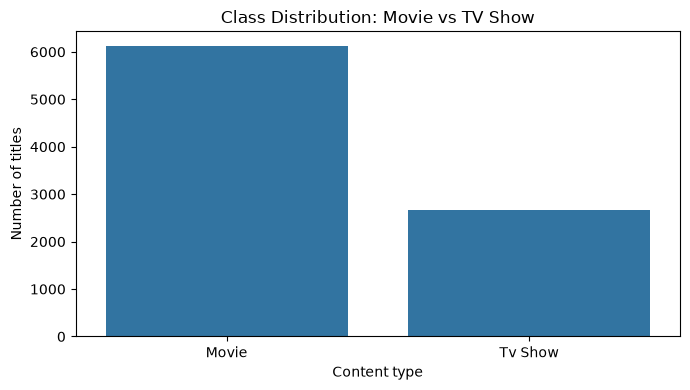

In [5]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="type", order=df["type"].value_counts().index)
plt.title("Class Distribution: Movie vs TV Show")
plt.xlabel("Content type")
plt.ylabel("Number of titles")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "class_distribution.png", dpi=150)
plt.show()

## 4. Feature selection

The target column is `type`. It must **never** be included in the model inputs because that would leak the answer.

We also exclude `show_id` (identifier) and `title` (high-cardinality title text, not part of this baseline). Remaining columns such as `director`, `country`, `date_added`, `release_year`, `rating`, `duration`, and `listed_in` can be used if they exist. The pipeline imputes missing feature values and one-hot encodes categorical features.

In [6]:
TARGET = "type"
DROP_COLUMNS = [c for c in ["show_id", "title"] if c in df.columns]
X = df.drop(columns=[TARGET] + DROP_COLUMNS, errors="ignore")
y = df[TARGET].astype(str)

if X.shape[1] == 0:
    raise ValueError("No predictor columns available after removing target/identifier columns.")

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

print("Excluded from predictors:", [TARGET] + DROP_COLUMNS)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Feature matrix shape:", X.shape)

Excluded from predictors: ['type', 'show_id', 'title']
Numeric features: ['release_year']
Categorical features: ['director', 'country', 'date_added', 'rating', 'duration', 'listed_in']
Feature matrix shape: (8790, 7)


## 5. Train/test split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Training rows: {len(X_train):,}")
print(f"Testing rows:  {len(X_test):,}")
print("\nTraining class proportions:")
display((y_train.value_counts(normalize=True) * 100).round(2).to_frame("percentage"))

Training rows: 7,032
Testing rows:  1,758

Training class proportions:


,percentage
type,
Movie,69.7
Tv Show,30.3


## 6. Build preprocessing and classification pipelines

In [8]:
def build_preprocessor(X_reference):
    numeric_cols = X_reference.select_dtypes(include=["number"]).columns.tolist()
    categorical_cols = [c for c in X_reference.columns if c not in numeric_cols]

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=2)),
    ])

    transformers = []
    if numeric_cols:
        transformers.append(("numeric", numeric_pipeline, numeric_cols))
    if categorical_cols:
        transformers.append(("categorical", categorical_pipeline, categorical_cols))
    return ColumnTransformer(transformers=transformers, remainder="drop")

models = {
    "Dummy Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=250, random_state=RANDOM_STATE,
        class_weight="balanced_subsample", min_samples_leaf=2, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=250, random_state=RANDOM_STATE,
        class_weight="balanced", min_samples_leaf=2, n_jobs=-1
    ),
}
print("Models to compare:", list(models.keys()))

Models to compare: ['Dummy Baseline', 'Logistic Regression', 'Random Forest', 'Extra Trees']


## 7. Train models and compare test-set performance

In [9]:
fitted_models = {}
rows = []

for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessor", build_preprocessor(X_train)),
        ("model", estimator),
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    fitted_models[name] = pipeline
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision_weighted": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "recall_weighted": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "f1_weighted": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "f1_macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
    })

results = pd.DataFrame(rows).sort_values("f1_macro", ascending=False).reset_index(drop=True)
display(results.style.format({
    "accuracy": "{:.4f}",
    "precision_weighted": "{:.4f}",
    "recall_weighted": "{:.4f}",
    "f1_weighted": "{:.4f}",
    "f1_macro": "{:.4f}",
}))
results.to_csv(METRICS_DIR / "model_comparison.csv", index=False)

,model,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro
0,Logistic Regression,0.9966,0.9966,0.9966,0.9966,0.9960
1,Extra Trees,0.9932,0.9933,0.9932,0.9932,0.9920
2,Random Forest,0.9863,0.9865,0.9863,0.9864,0.9839
3,Dummy Baseline,0.6968,0.4856,0.6968,0.5723,0.4107


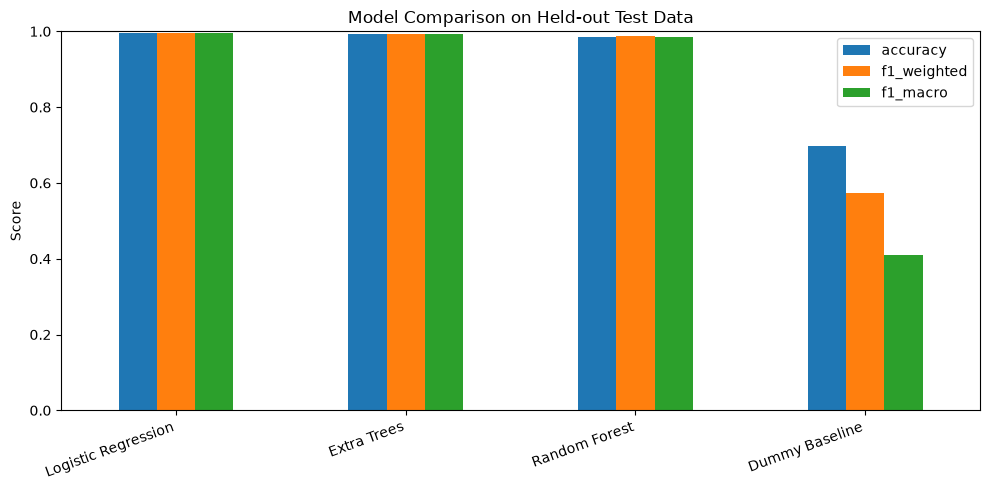

In [10]:
plot_results = results.set_index("model")[["accuracy", "f1_weighted", "f1_macro"]]
ax = plot_results.plot(kind="bar", figsize=(10, 5), ylim=(0, 1))
ax.set_title("Model Comparison on Held-out Test Data")
ax.set_ylabel("Score")
ax.set_xlabel("")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "model_comparison.png", dpi=150)
plt.show()

## 8. Evaluate the best non-baseline model

In [11]:
non_baseline = results[results["model"] != "Dummy Baseline"]
best_model_name = non_baseline.iloc[0]["model"]
best_model = fitted_models[best_model_name]
y_pred_best = best_model.predict(X_test)

print("Best model selected by macro F1:", best_model_name)
print("\nClassification report:")
print(classification_report(y_test, y_pred_best, zero_division=0))

Best model selected by macro F1: Logistic Regression

Classification report:
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1225
     Tv Show       1.00      0.99      0.99       533

    accuracy                           1.00      1758
   macro avg       1.00      1.00      1.00      1758
weighted avg       1.00      1.00      1.00      1758



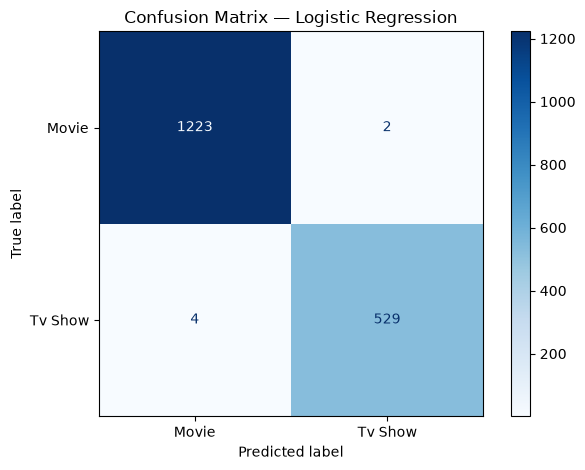

In [12]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred_best, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrix.png", dpi=150)
plt.show()

## 9. Save the selected model and evaluation summary

In [13]:
model_path = MODELS_DIR / "best_content_type_model.joblib"
joblib.dump(best_model, model_path)

summary = {
    "task": "Content Type Prediction Model",
    "target_column": TARGET,
    "classes": labels,
    "rows_after_cleaning": int(len(df)),
    "feature_columns": X.columns.tolist(),
    "excluded_columns": [TARGET] + DROP_COLUMNS,
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "random_state": RANDOM_STATE,
    "best_model_by_macro_f1": best_model_name,
    "metrics": results.to_dict(orient="records"),
}
(METRICS_DIR / "evaluation_summary.json").write_text(json.dumps(summary, indent=2))

print("Saved model:", model_path)
print("Saved metrics:", METRICS_DIR / "model_comparison.csv")
print("Saved summary:", METRICS_DIR / "evaluation_summary.json")

Saved model: /Users/mgs/Downloads/content-type-prediction/models/best_content_type_model.joblib
Saved metrics: /Users/mgs/Downloads/content-type-prediction/reports/metrics/model_comparison.csv
Saved summary: /Users/mgs/Downloads/content-type-prediction/reports/metrics/evaluation_summary.json


## 10. Try a prediction on a sample from the test set

In [14]:
sample = X_test.iloc[[0]]
actual_label = y_test.iloc[0]
predicted_label = best_model.predict(sample)[0]

print("Actual content type:   ", actual_label)
print("Predicted content type:", predicted_label)
display(sample.T.rename(columns={sample.index[0]: "sample_value"}))

Actual content type:    Movie
Predicted content type: Movie


,sample_value
director,"Fluvio Iannuci, Roly Santos"
country,Italy
date_added,5/1/2018
release_year,2017
rating,TV-PG
duration,69 min
listed_in,"Documentaries, International Movies"


## 11. Conclusion template

After running all cells, record your actual findings:
- **Best model:** use the model printed in Section 8.
- **Accuracy:** read the corresponding value in `model_comparison.csv`.
- **Precision, Recall and F1-score:** use the classification report above.
- **Confusion matrix:** use the plot in Section 8.
- **Limitations:** this is a supervised classification experiment on this dataset; results depend on available features, missing values, and class balance. Do not claim that the model generalizes to all streaming platforms without additional validation.

**Submission evidence:** save screenshots of the dataset inspection, class distribution, model comparison table/chart, classification report, and confusion matrix.